In [250]:
import numpy as np
X = np.array([
    [0.5],
    [1.0],
    [1.5],
    [2.0],
    [2.5],
    [3.0],
    [3.5],
    [4.0]
])
Y = np.array([0, 0, 1, 0, 0, 1, 1, 1])

In [251]:
def convert_one_hot(y, k):
    one_hot = np.zeros((len(y), k))
    one_hot[np.arange(len(y)), y] = 1
    return one_hot

n_classes = 2
Y_onehot = convert_one_hot(Y, n_classes)
Y_onehot

array([[1., 0.],
       [1., 0.],
       [0., 1.],
       [1., 0.],
       [1., 0.],
       [0., 1.],
       [0., 1.],
       [0., 1.]])

In [252]:
X = np.hstack([np.ones((len(X), 1)), X])
X

array([[1. , 0.5],
       [1. , 1. ],
       [1. , 1.5],
       [1. , 2. ],
       [1. , 2.5],
       [1. , 3. ],
       [1. , 3.5],
       [1. , 4. ]])

In [253]:
def softmax_function(z):
    return np.exp(z) / np.sum(np.exp(z))

def predict(x, theta):
    z = theta.T.dot(x)
    y_hat = softmax_function(z)
    return y_hat

def compute_loss(y_hat, y):
    loss = -np.log(y.T.dot(y_hat))
    return loss

In [254]:
def compute_gradient(y_hat, y, x):
    gradient = x.dot((y_hat - y).T)
    return gradient


In [255]:
theta = np.array([[0.1, 0.2], [0.3, 0.4]])
theta
learning_rate = 0.01
losses = []
n_epochs = 50
n_samples = X.shape[0]

for epoch in range(n_epochs):
    for i in range(n_samples):
        xi = X[i]
        yi = Y_onehot[i]
        
        xi = xi.reshape((2, 1))
        yi = yi.reshape((2, 1))

        y_hat = predict(xi, theta)

        loss = compute_loss(y_hat, yi)

        losses.append(loss[0])

        gradient = compute_gradient(y_hat, yi, xi)

        theta = theta - learning_rate * gradient


In [256]:
print(losses)

[array([0.77095705]), array([0.78930614]), array([0.59638603]), array([0.84387736]), array([0.83263869]), array([0.59678406]), array([0.5419307]), array([0.47729242]), array([0.77415227]), array([0.80152126]), array([0.57933817]), array([0.87495859]), array([0.8719218]), array([0.56095173]), array([0.50429719]), array([0.44028724]), array([0.77441562]), array([0.80907169]), array([0.56770639]), array([0.89803862]), array([0.90200281]), array([0.53484745]), array([0.47679314]), array([0.41320503]), array([0.77251732]), array([0.81312077]), array([0.55995434]), array([0.91497054]), array([0.92493381]), array([0.51552566]), array([0.45628711]), array([0.39292456]), array([0.7690297]), array([0.81454739]), array([0.55502164]), array([0.92720269]), array([0.9423518]), array([0.50102091]), array([0.44071448]), array([0.3774095]), array([0.76437796]), array([0.81401275]), array([0.55216243]), array([0.93585105]), array([0.95553569]), array([0.48999149]), array([0.42868007]), array([0.3652957]

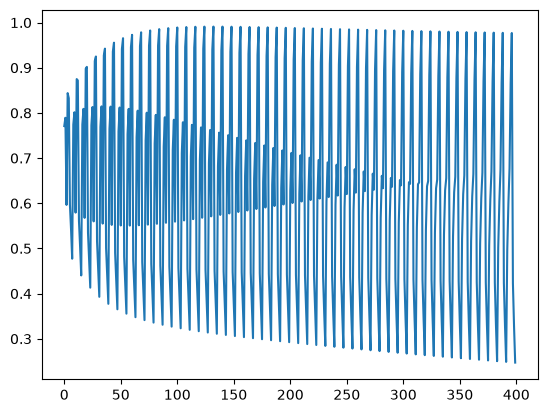

In [257]:
# Visualization
import matplotlib.pyplot as plt
plt.plot(losses)
plt.show()

In [258]:
x_test = np.array([1.0, 0.5]).reshape((2, 1))
y_hat = predict(x_test, theta)
print(y_hat)

[[0.61092888]
 [0.38907112]]


In [ ]:
print(np.argmax(y_hat, axis = 1))